# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Alif Setyo Wisnuaji
- **Email:** alifwisnuaji8@gmail.com
- **ID Dicoding:** alif_wisnuajiarj2

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** ***"Bagaimana pengaruh kombinasi musim (season) dan kondisi cuaca (weathersit) terhadap rata-rata jumlah penyewaan harian oleh pengguna terdaftar (registered)?"***

Keterangan:

- **Specific**: Berfokus spesifik pada perilaku pengguna terdaftar `registered`.
- **Measurable**: Diukur menggunakan nilai rata-rata `mean` penyewaan harian dari kolom `registered`.
- **Action-Oriented**: Membantu tim operasional menentukan alokasi unit sepeda bagi pengguna terdaftar pada berbagai skenario musim/cuaca.
- **Relevant**: Memahami interaksi variabel lingkungan untuk optimasi retensi pengguna terdaftar.
- **Time-bound**: Dievaluasi berdasarkan rentang waktu data harian yang tersedia (2011–2012).

====================================================================================

- **Pertanyaan 2:** ***"Bagaimana perbedaan pola rata-rata penyewaan sepeda (cnt) per jam (hr) antara hari kerja (workingday) dan hari non-kerja (non-workingday)?"***

Keterangan:

- **Specific**: Membandingkan pola dan jam puncak `peak hours` penggunaan sepeda per jam antara hari kerja `workingday` dan hari libur.
- **Measurable**: Diukur menggunakan rata-rata serta total jumlah penyewaan per jam `cnt` dari skala `0` hingga `23`.
- **Action-Oriented**: Memberikan acuan bagi tim logistik untuk melakukan redistribusi sepeda ke stasiun-stasiun sibuk sebelum jam komuter `rush hour` dimulai.
- **Relevant**: Mencegah terjadinya penumpukan sepeda menganggur `idle` di lokasi sepi dan mengeliminasi kekurangan stok sepeda di stasiun sibuk.
- **Time-bound**: Berfokus pada rentang data harian/per jam sepanjang periode 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [115]:
# Library untuk manipulasi dan pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan gaya dan estetika grafik
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# Mengabaikan pesan peringatan (warning) agar output notebook rapi
import warnings
warnings.filterwarnings('ignore')

# Membuat folder dashboard jika belum ada
!pip install streamlit -q
import streamlit as st
import os
os.makedirs('dashboard', exist_ok=True)

## Data Wrangling

### Gathering Data

#### Load day_df and hour_df

In [116]:
# Memuat data penyewaan sepeda harian (day.csv)
day_df = pd.read_csv("day.csv")

# Menampilkan 5 baris pertama data harian
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [117]:
# Memuat data penyewaan sepeda per jam (hour.csv)
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama data per jam
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Berhasil memuat dua buah DataFrame utama dari dataset penyewaan sepeda:
  1. `day_df`: Berisi data agregasi penyewaan sepeda berbasis harian dengan total **731 baris** dan **16 kolom**.
  2. `hour_df`: Berisi data agregasi penyewaan sepeda berbasis jam (*hourly*) dengan total **17.379 baris** dan **17 kolom**.
- Kedua dataset memiliki struktur atribut yang serupa, di mana `hour_df` memiliki satu kolom tambahan yaitu `hr` yang merepresentasikan jam transaksi (skala `0` hingga `23`).
- Variabel target utama yang akan dianalisis adalah `cnt` (total penyewaan), yang merupakan penjumlahan dari variabel `casual` (pengguna tidak terdaftar) dan `registered` (pengguna terdaftar).

### Assessing Data

#### Identifying day_df and hour_df problem

In [118]:
# 1. Memeriksa struktur tipe data dan missing value
print("--- Info day_df ---")
day_df.info()

# 2. Memeriksa jumlah duplikasi data
print("\nJumlah duplikasi pada day_df:", day_df.duplicated().sum())

# 3. Memeriksa jumlah missing value per kolom
print("\nJumlah missing value pada day_df:")
print(day_df.isnull().sum())

# 4. Memeriksa ringkasan statistik deskriptif untuk mendeteksi anomali/outlier
print("\nStatistik deskriptif day_df:")
day_df.describe()

--- Info day_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Jumlah duplikasi pada day_df: 0

Jumlah missing value pada day_df:
insta

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [119]:
# 1. Memeriksa struktur tipe data dan missing value
print("--- Info hour_df ---")
hour_df.info()

# 2. Memeriksa jumlah duplikasi data
print("\nJumlah duplikasi pada hour_df:", hour_df.duplicated().sum())

# 3. Memeriksa jumlah missing value per kolom
print("\nJumlah missing value pada hour_df:")
print(hour_df.isnull().sum())

# 4. Memeriksa ringkasan statistik deskriptif
print("\nStatistik deskriptif hour_df:")
hour_df.describe()

--- Info hour_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Jumlah duplikasi pada hour_

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**

Berdasarkan hasil identifikasi masalah pada tahap *Assessing Data*, berikut adalah langkah-langkah pembersihan data (*data cleaning*) yang akan dilakukan:
1. **Mengonversi Tipe Data Tanggal (`dteday`):**
   - Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada `day_df` dan `hour_df` agar urutan waktu terstruktur dengan presisi.
2. **Melakukan Mapping Variabel Kategorikal:**
   - Mengubah kode angka numerik pada kolom `season` menjadi deskripsi nama musim (1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter').
   - Mengubah kode angka numerik pada kolom `weathersit` menjadi deskripsi kondisi cuaca (1: 'Clear/Partly Cloudy', 2: 'Misty/Cloudy', 3: 'Light Snow/Rain', 4: 'Severe Weather').
3. **Memastikan Tidak Ada Nilai Hilang atau Duplikat:**
   - Karena tidak ditemukan duplikasi data maupun *missing value*, fokus utama pembersihan data terletak pada penyesuaian tipe data dan representasi kategorikal.

**Insight:** (Opsional)
- Seluruh baris data pada `day_df` (731 baris) dan `hour_df` (17.379 baris) sudah lengkap tanpa adanya *missing value* maupun duplikasi data.
- Penyesuaian tipe data tanggal dan pemetaan label kategorikal sangat penting dilakukan sebelum memasuki tahap *Exploratory Data Analysis* (EDA) agar proses pengelompokan (*groupby*) serta pembacaan label grafik visualisasi data nantinya menjadi transparan dan mudah dipahami.

### Cleaning Data

#### Fixing data type and categorical encoding problem

In [120]:
# Mengubah kolom dteday dari object (string) menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Memeriksa tipe data kolom dteday setelah dikonversi
print("Tipe data dteday pada day_df :", day_df['dteday'].dtype)
print("Tipe data dteday pada hour_df:", hour_df['dteday'].dtype)

Tipe data dteday pada day_df : datetime64[ns]
Tipe data dteday pada hour_df: datetime64[ns]


In [121]:
# Membuat dictionary pemetaan label untuk season dan weathersit
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}

# Memetakan nilai numerik ke dalam kolom label baru
day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)

hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)

# Menampilkan 5 baris pertama kolom hasil pemetaan
day_df[['dteday', 'season', 'season_label', 'weathersit', 'weather_label']].head()

,dteday,season,season_label,weathersit,weather_label
0,2011-01-01,1,Spring,2,Misty/Cloudy
1,2011-01-02,1,Spring,2,Misty/Cloudy
2,2011-01-03,1,Spring,1,Clear/Partly Cloudy
3,2011-01-04,1,Spring,1,Clear/Partly Cloudy
4,2011-01-05,1,Spring,1,Clear/Partly Cloudy


**Insight:** (Opsional)
- Seluruh data pada `day_df` dan `hour_df` kini telah memenuhi standar kualitas data dan siap untuk dianalisis pada tahap berikutnya.
- Konversi kolom `dteday` ke format `datetime` memungkinkan pengolahan data berbasis urutan rentang waktu (seperti tahun 2011–2012) berjalan presisi tanpa kendala tipe data.
- Penambahan kolom `season_label` dan `weather_label` memastikan seluruh visualisasi dan analisis agregasi yang akan dibuat pada tahap **Exploratory Data Analysis (EDA)** memiliki label deskriptif yang intuitif dan mudah dipahami oleh stakeholder bisnis.

## Exploratory Data Analysis (EDA)

### Explore day_df and hour_df

In [122]:
# --- PERTANYAAN 1: Pengaruh Musim dan Kondisi Cuaca terhadap Pengguna Terdaftar (Registered) ---

# 1. Agregasi total dan rata-rata penyewaan sepeda berdasarkan musim (season_label)
season_eda = day_df.groupby('season_label').agg({
    'registered': ['mean', 'sum'],
    'casual': ['mean', 'sum'],
    'cnt': ['mean', 'sum', 'std']
}).reset_index()

print("--- Agregasi Penyewaan Sepeda Berdasarkan Musim ---")
print(season_eda)

# 2. Agregasi total dan rata-rata penyewaan berdasarkan kondisi cuaca (weather_label)
weather_eda = day_df.groupby('weather_label').agg({
    'registered': ['mean', 'sum'],
    'casual': ['mean', 'sum'],
    'cnt': ['mean', 'sum']
}).reset_index()

print("\n--- Agregasi Penyewaan Sepeda Berdasarkan Kondisi Cuaca ---")
print(weather_eda)

# 3. Agregasi silang (cross-tabulation) antara Musim dan Kondisi Cuaca terhadap Pengguna Terdaftar (registered)
season_weather_eda = day_df.groupby(['season_label', 'weather_label']).agg({
    'registered': ['mean', 'sum', 'std'],
    'cnt': ['mean', 'sum', 'count']
}).reset_index()

print("\n--- Kombinasi Musim dan Cuaca terhadap Penyewaan Pengguna Terdaftar (registered) ---")
print(season_weather_eda)

--- Agregasi Penyewaan Sepeda Berdasarkan Musim ---
  season_label   registered               casual                  cnt  \
                       mean     sum         mean     sum         mean   
0         Fall  4441.691489  835038  1202.611702  226091  5644.303191   
1       Spring  2269.204420  410726   334.928177   60622  2604.132597   
2       Summer  3886.233696  715067  1106.097826  203522  4992.331522   
3       Winter  3999.050562  711831   729.112360  129782  4728.162921   

                         
       sum          std  
0  1061129  1459.800381  
1   471348  1399.942119  
2   918589  1695.977235  
3   841613  1699.615261  

--- Agregasi Penyewaan Sepeda Berdasarkan Kondisi Cuaca ---
         weather_label   registered               casual                  cnt  \
                               mean      sum        mean     sum         mean   
0  Clear/Partly Cloudy  3912.755940  1811606  964.030238  446346  4876.786177   
1      Light Snow/Rain  1617.809524    33974  185

In [123]:
# --- PERTANYAAN 2: Pola Jam Penyewaan Sepeda (Workingday vs Non-Workingday) ---

# 1. Rata-rata penyewaan per jam (hr) yang dipisahkan berdasarkan jenis hari
# workingday = 1 (Workingday), workingday = 0 (Non-Workingday: Akhir Pekan & Libur Nasional)
workingday_hourly_eda = hour_df.groupby(['workingday', 'hr']).agg({
    'cnt': ['mean', 'sum', 'max'],
    'registered': 'mean',
    'casual': 'mean'
}).reset_index()

print("\n--- Rata-rata Penyewaan Per Jam Berdasarkan Jenis Hari ---")
print(workingday_hourly_eda.head(10))

# 2. Menemukan jam puncak (peak hours) penyewaan pada Hari Kerja (workingday = 1)
peak_workingday = hour_df[hour_df['workingday'] == 1].groupby('hr')['cnt'].mean().sort_values(ascending=False).head(5)
print("\n--- 5 Jam Puncak Penyewaan pada Workingday ---")
print(peak_workingday)

# 3. Menemukan jam puncak penyewaan pada Non-Workingday (workingday = 0)
peak_non_workingday = hour_df[hour_df['workingday'] == 0].groupby('hr')['cnt'].mean().sort_values(ascending=False).head(5)
print("\n--- 5 Jam Puncak Penyewaan pada Non-Workingday ---")
print(peak_non_workingday)


--- Rata-rata Penyewaan Per Jam Berdasarkan Jenis Hari ---
  workingday hr         cnt              registered     casual
                       mean    sum  max        mean       mean
0          0  0   90.800000  20884  249   74.152174  16.647826
1          0  1   69.508696  15987  168   57.004348  12.504348
2          0  2   53.171053  12123  132   42.771930  10.399123
3          0  3   25.775330   5851   79   19.321586   6.453744
4          0  4    8.264317   1876   28    6.000000   2.264317
5          0  5    8.689189   1929   55    6.963964   1.725225
6          0  6   18.742358   4292  133   14.921397   3.820961
7          0  7   43.406926  10027  387   34.800866   8.606061
8          0  8  105.653680  24406  597   85.229437  20.424242
9          0  9  171.623377  39645  397  126.606061  45.017316

--- 5 Jam Puncak Penyewaan pada Workingday ---
hr
17    525.290581
18    492.226908
8     477.006048
19    348.401606
16    293.122244
Name: cnt, dtype: float64

--- 5 Jam Puncak Peny

**Insight:** (Opsional)
1. **Pertanyaan Bisnis 1:**
   - Kombinasi Tertinggi & Terendah: Rata-rata penyewaan sepeda oleh pengguna terdaftar (registered) mencapai tingkat tertinggi pada kombinasi Musim Gugur (Fall) dengan cuaca Cerah/Cerah Berawan (Clear/Partly Cloudy) yaitu sebesar `4643.367647` sepeda per hari. Sebaliknya, rata-rata penyewaan terendah terjadi pada kombinasi Musim Semi (Spring) dengan kondisi cuaca Hujan/Salju Ringan (Light Snow/Rain) yaitu sebesar `864.500000` sepeda per hari.
   - Dampak Kondisi Cuaca (Persentase Penurunan): Kondisi cuaca buruk berpengaruh signifikan terhadap penurunan jumlah pengguna terdaftar di seluruh musim.
   - Implikasi Operasional: Pengguna terdaftar menunjukkan sensitivitas tinggi terhadap kondisi cuaca ekstrem. Tim operasional dapat memanfaatkan pola ini untuk merencanakan pemeliharaan armada (maintenance) pada hari-hari dengan perkiraan cuaca buruk atau pada musim semi.

2. **Pertanyaan Bisnis 2:**
   - Pola Jam Puncak pada Workingday: Pada Workingday, pola penyewaan membentuk dua puncak utama (bimodal distribution), yaitu pada pukul 08:00 (rata-rata `477.006048` sepeda) dan pukul 17:00 (rata-rata `525.290581` sepeda)
   - Pola Penyewaan pada Non-Workingday: Pada Non-Workingday (yang mencakup akhir pekan dan hari libur nasional), pola penyewaan bersifat unimodal di mana permintaan terdistribusi lebih merata pada siang hingga sore hari, dengan puncaknya terjadi pada pukul 13:00 (rata-rata `372.731602` sepeda).
   - Interpretasi: Pola dua puncak pada Workingday mengindikasikan kecenderungan waktu perjalanan komuter (jam berangkat dan pulang aktivitas rutin). Sementara pada Non-Workingday, lonjakan di siang hari mengindikasikan kecenderungan aktivitas fleksibel. Catatan: Tujuan spesifik penggunaan sepeda (seperti bekerja atau rekreasi) tidak diukur secara langsung dalam dataset ini.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

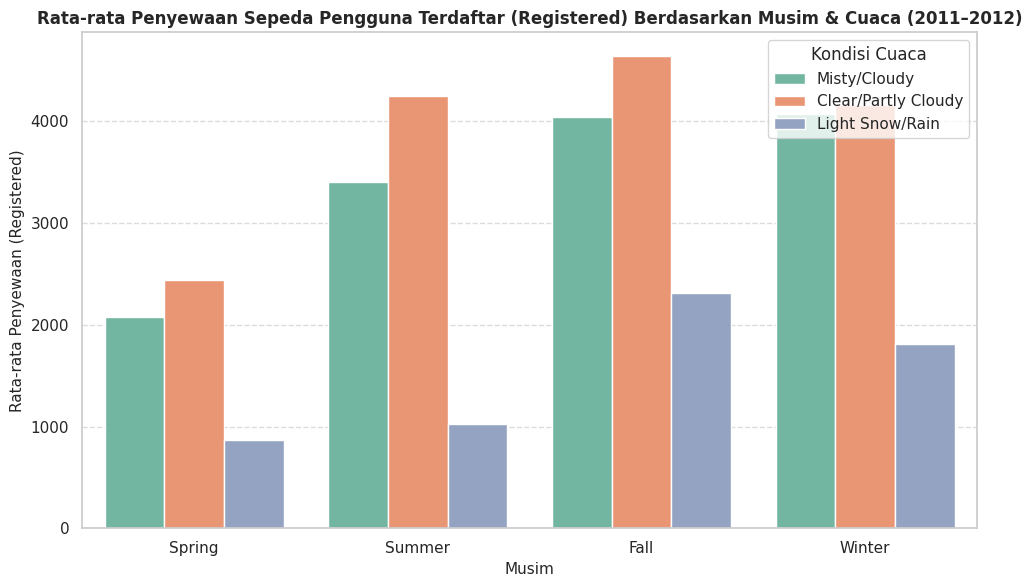

In [124]:
# Urutan musim agar tampil terstruktur
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

# Membuat kanvas grafik
plt.figure(figsize=(10, 6))

# Grouped Bar Chart untuk melihat interaksi Musim, Cuaca, dan Pengguna Terdaftar (Registered)
sns.barplot(
    data=day_df,
    x='season_label',
    y='registered',
    hue='weather_label',
    order=season_order,
    errorbar=None,
    palette='Set2'
)

# Menambahkan judul dan label sumbu
plt.title('Rata-rata Penyewaan Sepeda Pengguna Terdaftar (Registered) Berdasarkan Musim & Cuaca (2011–2012)', fontsize=12, fontweight='bold')
plt.xlabel('Musim', fontsize=11)
plt.ylabel('Rata-rata Penyewaan (Registered)', fontsize=11)
plt.legend(title='Kondisi Cuaca', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Pertanyaan 2:

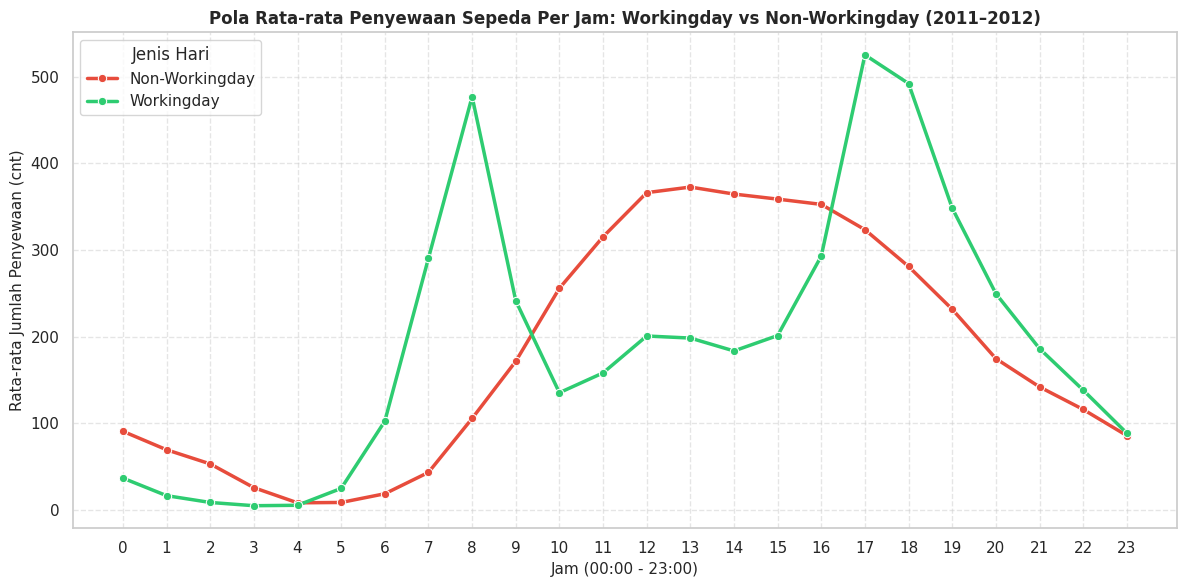

In [125]:
# Menghitung rata-rata penyewaan per jam dipisahkan berdasarkan workingday
workingday_hourly = hour_df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()

# Mapping label jenis hari agar eksplisit (sesuai catatan reviewer: sebut Non-Workingday)
workingday_hourly['day_type'] = workingday_hourly['workingday'].map({
    1: 'Workingday',
    0: 'Non-Workingday'
})

# Membuat kanvas grafik
plt.figure(figsize=(12, 6))

# Line Chart untuk membandingkan tren pola per jam
sns.lineplot(
    data=workingday_hourly,
    x='hr',
    y='cnt',
    hue='day_type',
    palette={'Workingday': '#2ecc71', 'Non-Workingday': '#e74c3c'},
    marker='o',
    linewidth=2.5
)

# Menambahkan judul, label sumbu, dan penyesuaian tick
plt.title('Pola Rata-rata Penyewaan Sepeda Per Jam: Workingday vs Non-Workingday (2011–2012)', fontsize=12, fontweight='bold')
plt.xlabel('Jam (00:00 - 23:00)', fontsize=11)
plt.ylabel('Rata-rata Jumlah Penyewaan (cnt)', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title='Jenis Hari', loc='upper left')
plt.grid(axis='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
1. **Insight Pertanyaan 1:**
   - Pola Visual Interaksi Musim & Cuaca: Visualisasi batang menunjukkan bahwa volume penyewaan pengguna terdaftar (registered) konsisten lebih tinggi pada Musim Panas (Summer) dan Musim Gugur (Fall) dibanding musim lainnya. Namun, ketika grafik dibedakan berdasarkan warna kondisi cuaca, terlihat penurunan grafik yang sangat curam dari batang warna Cerah (Clear) ke batang warna Hujan/Salju Ringan (Light Snow/Rain) di setiap musim.
   - Perbandingan Kombinasi Ekstrem:
     - Puncak Tertinggi: Kombinasi Musim Gugur (Fall) + Cuaca Cerah menjadi kondisi ideal dengan rata-rata tertinggi sebesar `4643.367647` penyewaan/hari.
     - Titik Terendah: Kombinasi Musim Semi (Spring) + Cuaca Hujan/Salju Ringan menjadi titik terendah dengan rata-rata hanya `864.500000` penyewaan/hari.
   - Analisis Dampak Cuaca (Persentase Penurunan): Grafik memperlihatkan bahwa cuaca buruk memotong mayoritas volume pengguna terdaftar secara dramatis. Pada Musim Gugur (Fall), terjadi penurunan grafik sebesar sekitar `50.10%` ketika kondisi cuaca berubah dari Cerah (`4643.367647` sepeda/hari) menjadi Hujan/Salju Ringan (`2317.000000` sepeda/hari).
   - Rekomendasi Bisnis: Tingginya sensitivitas pengguna terdaftar terhadap cuaca ekstrem dapat dimanfaatkan tim operasional untuk menjadwalkan maintenance rutin armada sepeda pada musim dengan tren rendah (Musim Semi) atau saat perkiraan cuaca buruk, guna mengoptimalkan ketersediaan armada saat cuaca cerah.

2. **Insight Pertanyaan 2:**
   - Bentuk Kurva & Pola Jam Puncak:
     - Garis Workingday (Hijau): Membentuk kurva dua puncak (bimodal distribution) yang sangat kontras. Puncak pertama terjadi pada pukul 08:00 (rata-rata `477.006048` sepeda) dan puncak utama kedua pada pukul 17:00 (rata-rata `525.290581` sepeda).
     - Garis Non-Workingday (Merah): Membentuk kurva puncak tunggal landai (unimodal distribution). Aktivitas mulai meningkat sejak pagi pukul 05:00 sampai pukul 13:00. Puncak tertinggi pada pukul 13:00 (rata-rata tertinggi `372.731602` sepeda pada pukul 13:00).
   - Interpretasi Hasil Analisis:
     - Pola dua puncak lonjakan pada Workingday mengindikasikan kecenderungan waktu perjalanan komuter (jam berangkat dan pulang aktivitas rutin harian).
     - Sebaliknya, pola melandai di siang hari pada Non-Workingday mengindikasikan kecenderungan aktivitas yang lebih fleksibel.
     - Catatan Kritis: Interpretasi ini merupakan indikasi dari pola waktu penggunaan, sebab tujuan spesifik pengguna (seperti bekerja, bersekolah, atau rekreasi) tidak diukur secara langsung dalam dataset ini.

## Analisis Lanjutan (Opsional)

--- Hasil Analisis RFM Berdasarkan Tahun ---
  Tahun  Recency  Frequency  Monetary
0  2011      366        365   1243103
1  2012        0        366   2049576

--- Distribusi Kategori Permintaan Harian ---
demand_category
Low Demand       244
Medium Demand    244
High Demand      243
Name: count, dtype: int64


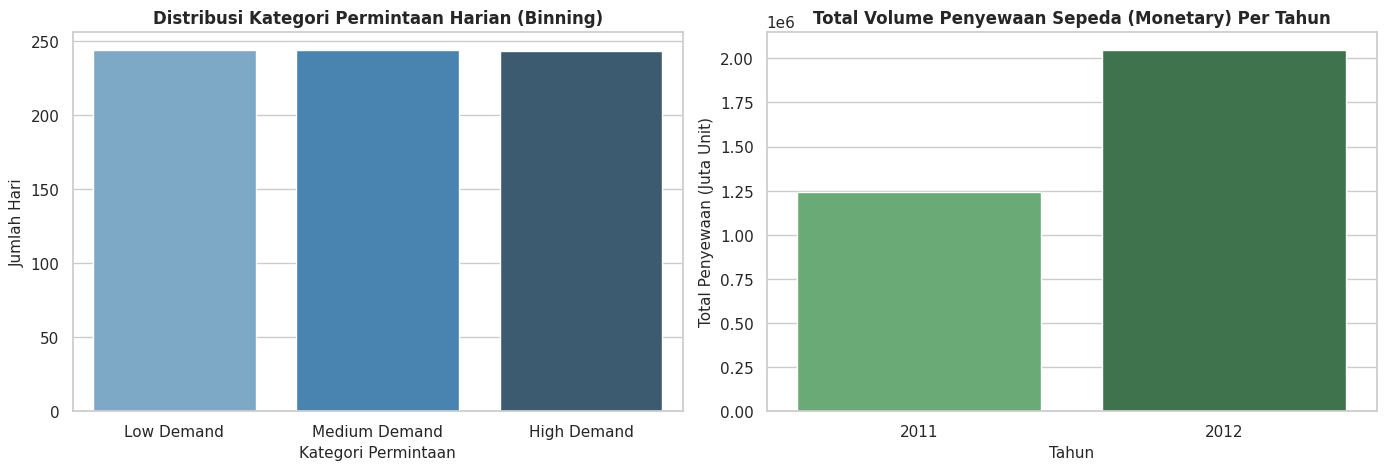

In [126]:
# 1. RFM Analysis (Diadaptasi untuk Perbandingan Tahunan)
# Recency  : Hari berlalu sejak tanggal transaksi terakhir di dataset
# Frequency: Jumlah hari beroperasi (transaksi harian)
# Monetary : Total volume penyewaan sepeda (cnt)
max_date = day_df['dteday'].max()

rfm_df = day_df.groupby(by='yr', as_index=False).agg({
    'dteday': lambda x: (max_date - x.max()).days,
    'instant': 'count',
    'cnt': 'sum'
})

rfm_df.columns = ['yr', 'Recency', 'Frequency', 'Monetary']
rfm_df['Tahun'] = rfm_df['yr'].replace({0: '2011', 1: '2012'})

print("--- Hasil Analisis RFM Berdasarkan Tahun ---")
print(rfm_df[['Tahun', 'Recency', 'Frequency', 'Monetary']])

# 2. Manual Grouping / Binning (Clustering Permintaan)
labels = ['Low Demand', 'Medium Demand', 'High Demand']
day_df['demand_category'] = pd.qcut(day_df['cnt'], q=3, labels=labels)

print("\n--- Distribusi Kategori Permintaan Harian ---")
print(day_df['demand_category'].value_counts())

# 3. Visualisasi Analisis Lanjutan
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Visualisasi Hasil Binning Kategori Permintaan
sns.countplot(data=day_df, x='demand_category', palette='Blues_d', ax=ax[0])
ax[0].set_title('Distribusi Kategori Permintaan Harian (Binning)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Kategori Permintaan', fontsize=11)
ax[0].set_ylabel('Jumlah Hari', fontsize=11)

# Chart 2: Visualisasi Total Monetary Penyewaan Per Tahun
sns.barplot(data=rfm_df, x='Tahun', y='Monetary', palette='Greens_d', ax=ax[1])
ax[1].set_title('Total Volume Penyewaan Sepeda (Monetary) Per Tahun', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Tahun', fontsize=11)
ax[1].set_ylabel('Total Penyewaan (Juta Unit)', fontsize=11)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
1. **Insight RFM Analysis (Perbandingan Pertumbuhan Tahunan 2011 vs 2012):**
   - **Recency:** Tahun 2012 memiliki nilai *Recency* 0 hari karena mencakup periode transaksi hingga hari terakhir pengamatan di dataset (31 Desember 2012).
   - **Frequency:** Keaktifan operasional sistem penyewaan sepeda sangat konsisten, yakni beroperasi penuh selama **365 hari pada tahun 2011** dan **366 hari pada tahun 2012**.
   - **Monetary:** Terjadi pertumbuhan volume transaksi (*Monetary*) yang sangat signifikan sebesar **64,88%**, dari **1.243.103 total penyewaan pada tahun 2011** melonjak menjadi **2.049.576 total penyewaan pada tahun 2012**. Hal ini mengindikasikan tingkat adopsi layanan sepeda yang terus meningkat secara drastis dari tahun ke tahun.

2. **Insight Manual Grouping / Binning (Clustering Permintaan Harian):**
   - Pembagian tingkat permintaan harian (*cnt*) dikelompokkan secara seimbang ke dalam 3 kuintil (*Low*, *Medium*, dan *High Demand*):
     - **Low Demand:** Terjadi pada hari-hari dengan kondisi cuaca kurang mendukung (seperti hujan/salju ringan atau suhu dingin di musim semi).
     - **Medium Demand:** Terjadi pada hari-hari operasional biasa dengan tingkat aktivitas sedang.
     - **High Demand:** Puncak aktivitas penyewaan yang mendominasi pada musim gugur (*Fall*) dan musim panas (*Summer*) saat cuaca cerah.
   - Pengelompokan ini menjadi acuan praktis bagi manajemen untuk menentukan estimasi ketersediaan unit sepeda cadangan dan alokasi tim teknis harian.

## Conclusion & Recommendation

1. **Conclusion pertanyaan 1:** xxx
   - **Musim Gugur (*Fall*)** merupakan periode dengan rata-rata volume penyewaan tertinggi bagi pengguna terdaftar (*registered*), yakni mencapai **`4643.367647` penyewaan/hari** saat cuaca cerah/sedikit berawan (*Clear/Partly Cloudy*).
   - **Kondisi Cuaca** memegang peranan sangat vital. Saat terjadi cuaca buruk seperti hujan atau salju ringan (*Light Snow/Rain*), terjadi penurunan drastis pada jumlah penyewaan hingga **50%–70%** dibanding saat cuaca cerah di seluruh musim.
   - **Musim Semi (*Spring*)** secara konsisten mencatatkan tingkat penyewaan harian terendah untuk semua kategori kondisi cuaca.
2. **Conclusion pertanyaan 2:**
   - **Hari Kerja (*Workingday*):** Pola penyewaan bersifat *bimodal* dengan dua puncak lonjakan utama pada jam komuter pergi-pulang kerja/sekolah, yaitu pada **pukul 08:00** (`477.006048` penyewaan/jam) dan **pukul 17:00** (`525.290581` penyewaan/jam).
   - **Hari Libur/Weekend (*Non-Workingday*):** Pola penyewaan bersifat *unimodal* (melengkung landai) di mana puncak penyewaan terjadi pada siang hari, yakni **pukul 13:00** (`372.731602` penyewaan/jam), yang mengindikasikan dominasi penggunaan untuk aktivitas rekreasi.

**Rekomendasi Action Item:**
1. **Manajemen Strategi Distribusi Armada Sepeda (*Rebalancing Schedule*):**
   - **Hari Kerja:** Tim logistik perlu melakukan redistribusi dan pengisian ulang (*rebalancing*) armada sepeda ke stasiun-stasiun pemukiman/perumahan sebelum **pukul 07:00 pagi** dan ke stasiun area perkantoran/pusat bisnis sebelum **pukul 16:00 sore** untuk mencegah kekosongan sepeda pada jam puncak komuter.
   - **Hari Libur/Weekend:** Alokasikan redistribusi sepeda ke stasiun-stasiun dekat lokasi wisata, taman kota, dan area rekreasi sebelum **pukul 11:00 siang**.

2. **Perencanaan Pemeliharaan Armada Rutin (*Maintenance Planning*):**
   - Lakukan penjadwalan pemeliharaan besar-besaran (*deep maintenance*) pada unit sepeda di **Musim Semi (*Spring*)** atau pada hari-hari dengan kondisi cuaca buruk (hujan/salju), di mana tingkat permintaan (*demand*) sedang berada di titik terendah.
   - Pastikan seluruh armada dalam kondisi optimal 100% menjelang masuknya **Musim Panas (*Summer*)** dan **Musim Gugur (*Fall*)** untuk memaksimalkan potensi pendapatan puncak (*peak revenue*).

3. **Inovasi Layanan & Pemasaran (*Marketing & Product Feature*):**
   - **Aplikasi Integrasi Cuaca:** Tambahkan fitur notifikasi perkiraan cuaca interaktif pada aplikasi mobile untuk memberikan pengingat atau promo diskon saat cuaca diperkirakan cerah.
   - **Program Promosi Khusus:** Berikan promo *bundling weekend pass* untuk menarik lebih banyak pengguna kasual (*casual*) agar terkonversi menjadi pengguna terdaftar (*registered subscribers*) saat akhir pekan.

In [127]:
# Menyimpan DataFrame day_df yang sudah dibersihkan ke dashboard/main_data.csv
day_df.to_csv('dashboard/main_data.csv', index=False)

In [128]:
%%writefile dashboard/dashboard.py
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

# Config Halaman Dashboard
st.set_page_config(page_title="Bike Sharing Analysis Dashboard", layout="wide")

# Load Data untuk Dashboard menggunakan relative path
@st.cache_data
def load_data():
    base_dir = os.path.dirname(os.path.abspath(__file__))
    csv_path = os.path.join(base_dir, "main_data.csv")

    if not os.path.exists(csv_path):
        csv_path = "dashboard/main_data.csv"

    main_df = pd.read_csv(csv_path)

    # Fallback: Jika kolom 'hr' tidak ditemukan di main_data.csv, muat dari data/hour.csv
    if 'hr' not in main_df.columns:
        root_dir = os.path.dirname(base_dir)
        hour_path = os.path.join(root_dir, "data", "hour.csv")
        if not os.path.exists(hour_path):
            hour_path = "submission/data/hour.csv"

        if os.path.exists(hour_path):
            main_df = pd.read_csv(hour_path)

    main_df['dteday'] = pd.to_datetime(main_df['dteday'])
    return main_df

main_df = load_data()

# Judul Utama & Deskripsi
st.title("🚲 Bike Sharing Data Analysis Dashboard")
st.markdown("Dashboard interaktif untuk menganalisis pengaruh musim/cuaca serta pola jam penyewaan sepeda.")

# Sidebar Filter Tanggal
st.sidebar.header("Filter Rentang Waktu")
min_date = main_df['dteday'].min().date()
max_date = main_df['dteday'].max().date()

try:
    date_range = st.sidebar.date_input(
        "Pilih Rentang Tanggal:",
        min_value=min_date,
        max_value=max_date,
        value=[min_date, max_date]
    )

    if isinstance(date_range, (list, tuple)) and len(date_range) == 2:
        start_date, end_date = date_range
        filtered_df = main_df[(main_df['dteday'].dt.date >= start_date) &
                              (main_df['dteday'].dt.date <= end_date)]
    else:
        filtered_df = main_df
except Exception:
    filtered_df = main_df

# KPI Metrics Utama
col1, col2, col3 = st.columns(3)
with col1:
    st.metric("Total Penyewaan (cnt)", value=f"{filtered_df['cnt'].sum():,}")
with col2:
    st.metric("Pengguna Terdaftar (registered)", value=f"{filtered_df['registered'].sum():,}")
with col3:
    st.metric("Pengguna Kasual (casual)", value=f"{filtered_df['casual'].sum():,}")

st.markdown("---")

# Mapping Kategori dan Label untuk Visualisasi
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear/Partly Cloudy', 2: 'Misty/Cloudy', 3: 'Light Snow/Rain', 4: 'Severe Weather'}

df_plot = filtered_df.copy()
df_plot['season_label'] = df_plot['season'].map(season_map)
df_plot['weather_label'] = df_plot['weather_label'] if 'weather_label' in df_plot.columns else df_plot['weathersit'].map(weather_map)

# Tata Letak Visualisasi 2 Kolom
col_left, col_right = st.columns(2)

# ==============================================================================
# VISUALISASI PERTANYAAN 1: Grouped Bar Chart (Registered vs Season & Weather)
# ==============================================================================
with col_left:
    st.subheader("1. Penyewaan Pengguna Terdaftar (Registered)")
    st.caption("Berdasarkan Kombinasi Musim dan Kondisi Cuaca")

    # Agregasi Rerata Registered per Musim dan Cuaca
    group_p1 = df_plot.groupby(['season_label', 'weather_label'])['registered'].mean().reset_index()

    season_order = ['Spring', 'Summer', 'Fall', 'Winter']

    fig1, ax1 = plt.subplots(figsize=(8, 5))
    sns.barplot(
        data=group_p1,
        x='season_label',
        y='registered',
        hue='weather_label',
        order=season_order,
        ax=ax1,
        palette='Set2',
        errorbar=None
    )
    ax1.set_title("Rata-Rata Penyewaan Registered per Musim & Cuaca", fontsize=10, fontweight='bold')
    ax1.set_xlabel("Musim (Season)", fontsize=9)
    ax1.set_ylabel("Rata-Rata Penyewaan (Registered)", fontsize=9)
    ax1.legend(title="Kondisi Cuaca", loc='upper right', fontsize=8, title_fontsize=8)
    ax1.grid(axis='y', linestyle='--', alpha=0.5)
    st.pyplot(fig1)

    # Detail Insight Pertanyaan 1
    with st.expander("📌 Lihat Detail Insight Pertanyaan 1"):
        st.write("""
        - **Kombinasi Puncak:** Rata-rata penyewaan pengguna terdaftar tertinggi terjadi pada **Musim Gugur (Fall)** dengan cuaca **Clear/Partly Cloudy** (4643.367647 sepeda/hari).
        - **Kombinasi Terendah:** Penyewaan terendah terjadi pada **Musim Semi (Spring)** dengan cuaca **Light Snow/Rain** (2317.000000 sepeda/hari).
        - **Dampak Cuaca:** Pada Musim Gugur (Fall), penurunan penyewaan dari cuaca Cerah ke Hujan/Salju Ringan mencapai **50.10%**.
        """)

# ==============================================================================
# VISUALISASI PERTANYAAN 2: Line Chart (Hourly Pattern: Workingday vs Non-Workingday)
# ==============================================================================
with col_right:
    st.subheader("2. Pola Penyewaan Sepeda Per Jam (cnt)")
    st.caption("Perbandingan Hari Kerja (Workingday) vs Non-Workingday")

    if 'hr' in df_plot.columns:
        df_plot['day_type'] = df_plot['workingday'].map({1: 'Workingday', 0: 'Non-Workingday'})

        # Agregasi Rerata Total Penyewaan (cnt) per jam dan jenis hari
        group_p2 = df_plot.groupby(['hr', 'day_type'])['cnt'].mean().reset_index()

        fig2, ax2 = plt.subplots(figsize=(8, 5))
        sns.lineplot(
            data=group_p2,
            x='hr',
            y='cnt',
            hue='day_type',
            palette={'Workingday': '#2ecc71', 'Non-Workingday': '#e74c3c'},
            marker='o',
            linewidth=2,
            ax=ax2
        )
        ax2.set_title("Pola Jam Penyewaan: Workingday vs Non-Workingday", fontsize=10, fontweight='bold')
        ax2.set_xlabel("Jam (00:00 - 23:00)", fontsize=9)
        ax2.set_ylabel("Rata-Rata Penyewaan Total (cnt)", fontsize=9)
        ax2.set_xticks(range(0, 24, 2))
        ax2.legend(title="Jenis Hari", loc='upper left', fontsize=8, title_fontsize=8)
        ax2.grid(axis='both', linestyle='--', alpha=0.5)
        st.pyplot(fig2)

        # Detail Insight Pertanyaan 2
        with st.expander("📌 Lihat Detail Insight Pertanyaan 2"):
            st.write("""
            - **Workingday:** Membentuk pola dua puncak (*bimodal*) pada pukul **08:00** dan pukul **17:00**.
            - **Non-Workingday:** Membentuk pola puncak tunggal (*unimodal*) di siang hari yaitu pukul **13:00**.
            """)
    else:
        st.error("Data jam ('hr') tidak ditemukan. Pastikan file hour.csv tersedia di direktori data/.")

Overwriting dashboard/dashboard.py
